In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("food_delivery_cleaned.csv") 
print("Dataset Shape:") 
print(df.shape)

Dataset Shape:
(100000, 25)


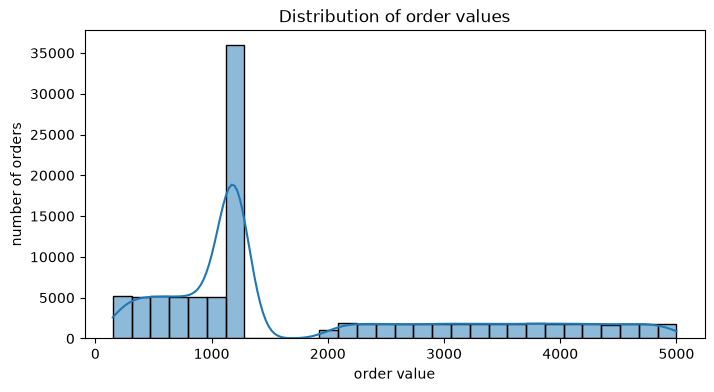

In [12]:
#Distribution of order values
plt.figure(figsize=(8,4))
sns.histplot(df['Order_Value'],bins=30,kde=True)
plt.title("Distribution of order values")
plt.xlabel("order value")
plt.ylabel("number of orders")
plt.show()

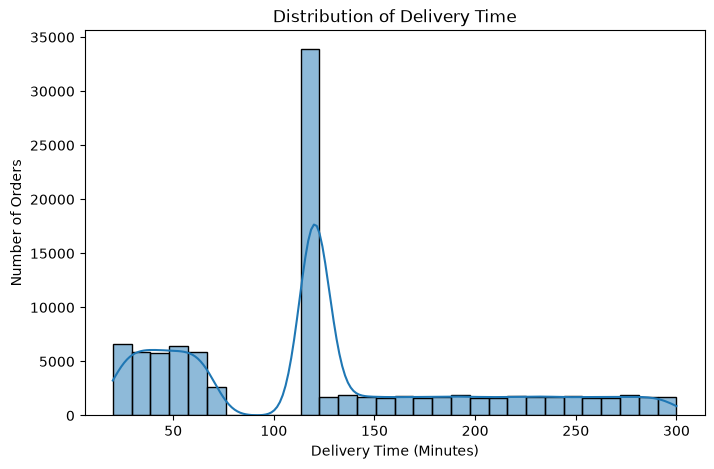

In [14]:
#Delivery Time Distribution

plt.figure(figsize=(8, 5)) 
sns.histplot( df["Delivery_Time_Min"], bins=30, kde=True ) 
plt.title("Distribution of Delivery Time") 
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Orders")
plt.show()

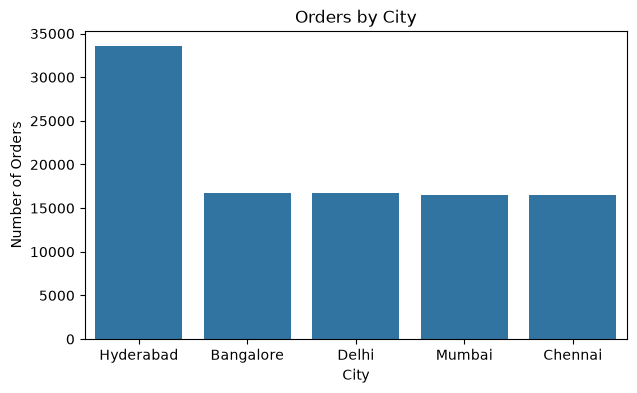

In [20]:
# City-wise Order Analysis
plt.figure(figsize=(7,4)) 
sns.barplot(x=df['City'].value_counts().index,
             y=df['City'].value_counts().values)

plt.title("Orders by City") 
plt.xlabel("City") 
plt.ylabel("Number of Orders") 
plt.show()


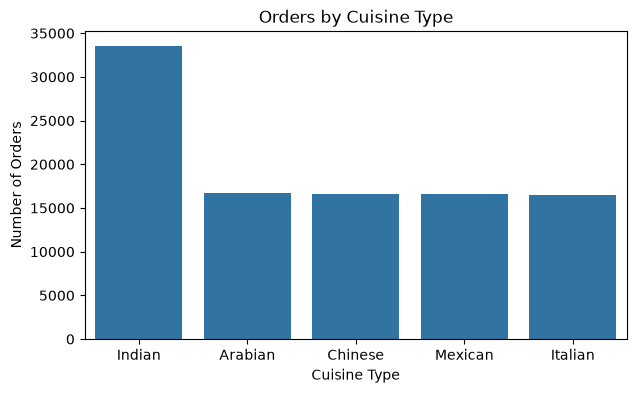

In [22]:
# cuisine-wise Order Analysis
plt.figure(figsize=(7,4)) 
sns.barplot(x=df['Cuisine_Type'].value_counts().index,
             y=df['Cuisine_Type'].value_counts().values)

plt.title("Orders by Cuisine Type") 
plt.xlabel("Cuisine Type") 
plt.ylabel("Number of Orders") 
plt.show()



Weekday vs Weekend Orders:
Day_Type
Weekday    71632
Weekend    28368
Name: count, dtype: int64


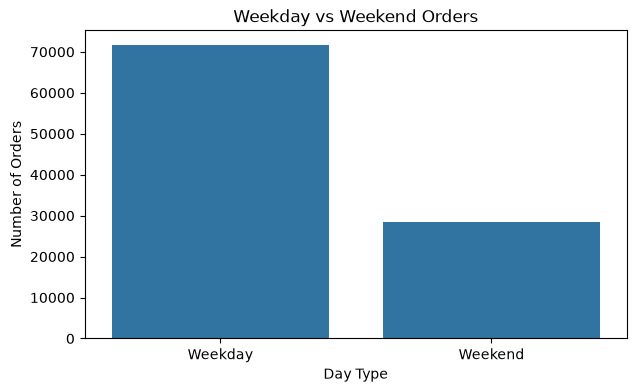

In [ ]:
# Weekday vs Weekend Analysis
df["Day_Type"] = df["Order_Date"].dt.dayofweek.apply(lambda x: "Weekend" if x >= 5 else "Weekday")
day_type_orders = df["Day_Type"].value_counts()
print("\nWeekday vs Weekend Orders:")
print(day_type_orders)

# Bar Chart
plt.figure(figsize=(7, 4))
sns.barplot(x=day_type_orders.index, y=day_type_orders.values)
plt.title("Weekday vs Weekend Orders")
plt.xlabel("Day Type")
plt.ylabel("Number of Orders")
plt.show()

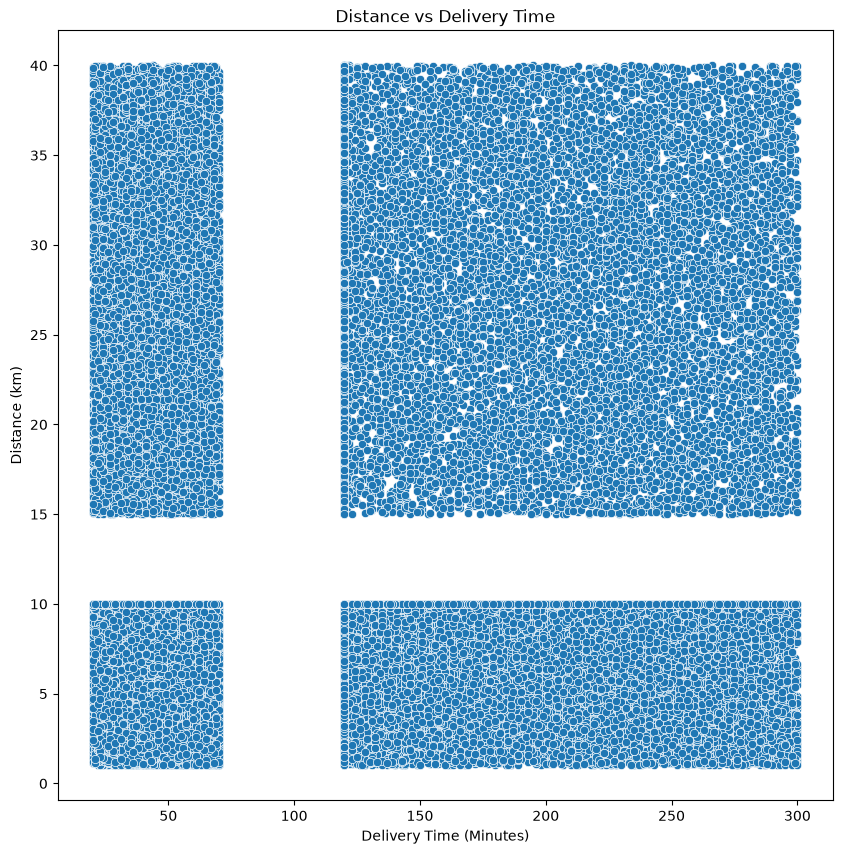

In [39]:
#Distance vs delivery delay relationship 
plt.figure(figsize=(10,10))
sns.scatterplot(data=df,y="Distance_km",x="Delivery_Time_Min" )
plt.title("Distance vs Delivery Time")
plt.ylabel("Distance (km)")
plt.xlabel("Delivery Time (Minutes)")
plt.show()


Cancellation Reasons:
Cancellation_Reason
Unknown               6005
Late Delivery         3059
Customer Cancelled    2993
Restaurant Issue      2979
Name: count, dtype: int64


(array([0, 1, 2, 3]),
 [Text(0, 0, 'Unknown'),
  Text(1, 0, 'Late Delivery'),
  Text(2, 0, 'Customer Cancelled'),
  Text(3, 0, 'Restaurant Issue')])

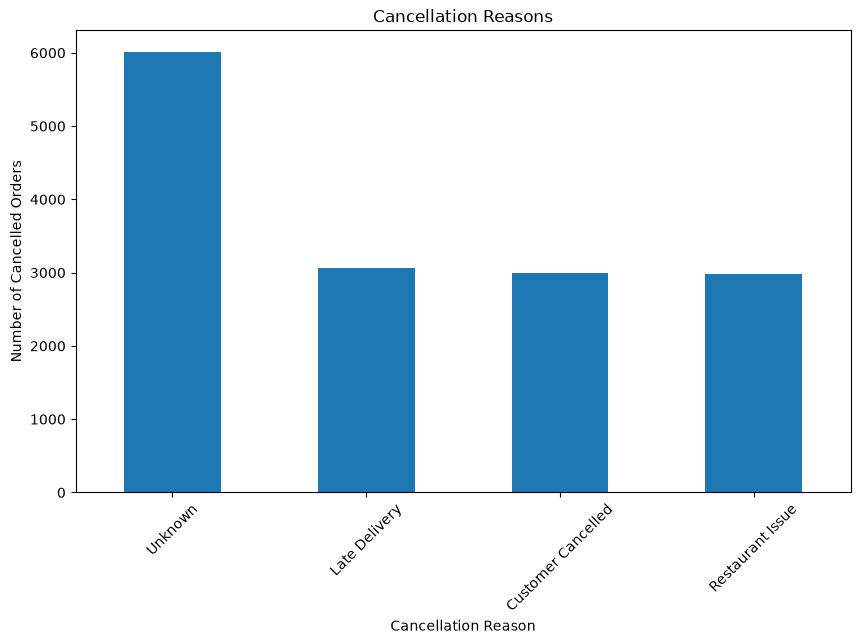

In [32]:
#Cancellation reasons analysis 
cancelled = df[ df["Order_Status"] == "Cancelled" ] 
cancellation_counts = ( cancelled["Cancellation_Reason"] .value_counts() )
print("\nCancellation Reasons:")
print(cancellation_counts) 
plt.figure(figsize=(10, 6)) 
cancellation_counts.plot(kind="bar") 
plt.title("Cancellation Reasons") 
plt.xlabel("Cancellation Reason") 
plt.ylabel("Number of Cancelled Orders") 
plt.xticks(rotation=45)

                   Customer_Age  Delivery_Time_Min  Distance_km  Order_Value  \
Customer_Age       1.000000e+00          -0.010294    -0.001426    -0.001997   
Delivery_Time_Min -1.029405e-02           1.000000     0.002227     0.002213   
Distance_km       -1.425891e-03           0.002227     1.000000     0.001440   
Order_Value       -1.997086e-03           0.002213     0.001440     1.000000   
Discount_Applied   2.131765e-03           0.000584     0.003174    -0.000288   
Final_Amount      -2.157683e-03           0.002161     0.001188     0.996936   
Delivery_Rating    3.478566e-07           0.002707    -0.001065     0.001392   
Restaurant_Rating  1.690998e-03           0.002651     0.002851    -0.003619   
Profit_Margin      1.091192e-03          -0.001280     0.002478    -0.002426   

                   Discount_Applied  Final_Amount  Delivery_Rating  \
Customer_Age               0.002132     -0.002158     3.478566e-07   
Delivery_Time_Min          0.000584      0.002161     2.706

<Axes: >

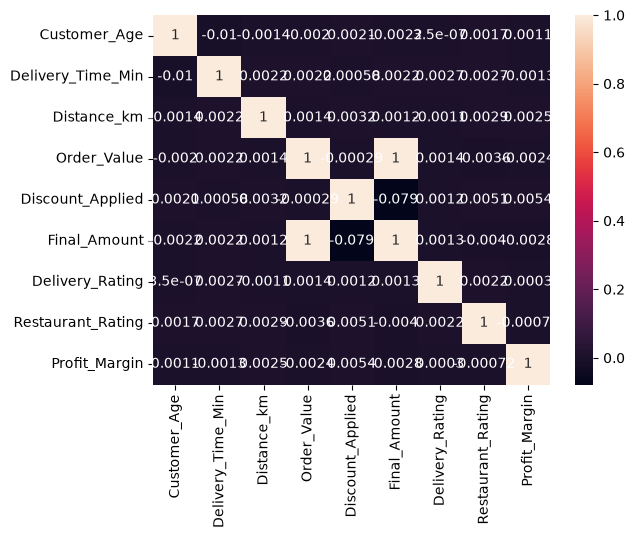

In [37]:
num_column = df.select_dtypes(include='number').columns.tolist()
print(df[num_column].corr())
corr_info = df[num_column].corr()
sns.heatmap(corr_info,annot=True)